
# EduPredict — Inteligência Artificial para Apoio Pedagógico

## 1. Contexto do problema

O EduPredict é um protótipo de aprendizado de máquina
voltado à análise de indicadores de desempenho escolar.

O projeto utiliza o dataset público Student Performance
Factors, disponibilizado no Kaggle, para investigar
relações entre fatores acadêmicos e o desempenho dos
estudantes.

### Objetivo

Desenvolver uma rede neural artificial do tipo
Multilayer Perceptron (MLP) para classificar faixas
de desempenho acadêmico a partir de variáveis
disponíveis no conjunto de dados.

### Aplicação prática

O modelo poderá servir como demonstração de uma
ferramenta de apoio à análise pedagógica.

As previsões não devem ser utilizadas isoladamente
para decisões sobre estudantes.

### Fonte dos dados

https://www.kaggle.com/datasets/lainguyn123/student-performance-factors

### Tecnologias

- Python
- Pandas e NumPy
- Scikit-learn
- Matplotlib e Seaborn
- Jupyter Notebook
- FastAPI
- UV


In [2]:

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("EduPredict — Ambiente de análise inicializado!")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)


EduPredict — Ambiente de análise inicializado!
Pandas: 3.1.1
NumPy: 2.5.5


In [3]:

# Localizar a raiz do projeto
diretorio_atual = Path.cwd()

if (diretorio_atual / "data" / "dataset.csv").exists():
    caminho_dataset = diretorio_atual / "data" / "dataset.csv"
elif (diretorio_atual.parent / "data" / "dataset.csv").exists():
    caminho_dataset = diretorio_atual.parent / "data" / "dataset.csv"
else:
    raise FileNotFoundError(
        "Arquivo data/dataset.csv não encontrado."
    )

df = pd.read_csv(caminho_dataset)

print("Dataset carregado com sucesso!")
print(f"Registros: {df.shape[0]}")
print(f"Colunas: {df.shape[1]}")

display(df.head())


Dataset carregado com sucesso!
Registros: 6607
Colunas: 20


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [4]:

print("=== COLUNAS DISPONÍVEIS ===")
print(df.columns.tolist())

print("\n=== TIPOS DE DADOS ===")
display(df.dtypes.to_frame("Tipo"))

print("\n=== VALORES AUSENTES ===")
display(df.isnull().sum().to_frame("Nulos"))

print("\n=== ESTATÍSTICAS DESCRITIVAS ===")
display(df.describe(include="all").T)


=== COLUNAS DISPONÍVEIS ===
['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender', 'Exam_Score']

=== TIPOS DE DADOS ===


,Tipo
Hours_Studied,int64
Attendance,int64
Parental_Involvement,str
Access_to_Resources,str
Extracurricular_Activities,str
Sleep_Hours,int64
Previous_Scores,int64
Motivation_Level,str
Internet_Access,str
Tutoring_Sessions,int64



=== VALORES AUSENTES ===


,Nulos
Hours_Studied,0
Attendance,0
Parental_Involvement,0
Access_to_Resources,0
Extracurricular_Activities,0
Sleep_Hours,0
Previous_Scores,0
Motivation_Level,0
Internet_Access,0
Tutoring_Sessions,0



=== ESTATÍSTICAS DESCRITIVAS ===


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Hours_Studied,6607.0,NaN,NaN,NaN,19.975329,5.990594,1.0,16.0,20.0,24.0,44.0
Attendance,6607.0,NaN,NaN,NaN,79.977448,11.547475,60.0,70.0,80.0,90.0,100.0
Parental_Involvement,6607,3,Medium,3362,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Access_to_Resources,6607,3,Medium,3319,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Extracurricular_Activities,6607,2,Yes,3938,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sleep_Hours,6607.0,NaN,NaN,NaN,7.02906,1.46812,4.0,6.0,7.0,8.0,10.0
Previous_Scores,6607.0,NaN,NaN,NaN,75.070531,14.399784,50.0,63.0,75.0,88.0,100.0
Motivation_Level,6607,3,Medium,3351,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Internet_Access,6607,2,Yes,6108,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tutoring_Sessions,6607.0,NaN,NaN,NaN,1.493719,1.23057,0.0,1.0,1.0,2.0,8.0


In [5]:

print("=== QUALIDADE DO DATASET ===")

print(f"Total de registros: {len(df)}")
print(f"Registros duplicados: {df.duplicated().sum()}")

nulos = df.isna().sum()
percentuais = (nulos / len(df) * 100).round(2)

qualidade = pd.DataFrame({
    "Valores ausentes": nulos,
    "Percentual (%)": percentuais
})

display(qualidade[qualidade["Valores ausentes"] > 0])

print("\n=== DISTRIBUIÇÃO DA NOTA ===")
display(df["Exam_Score"].describe())


=== QUALIDADE DO DATASET ===
Total de registros: 6607
Registros duplicados: 0


,Valores ausentes,Percentual (%)
Teacher_Quality,78,1.18
Parental_Education_Level,90,1.36
Distance_from_Home,67,1.01



=== DISTRIBUIÇÃO DA NOTA ===


count    6607.000000
mean       67.235659
std         3.890456
min        55.000000
25%        65.000000
50%        67.000000
75%        69.000000
max       101.000000
Name: Exam_Score, dtype: float64

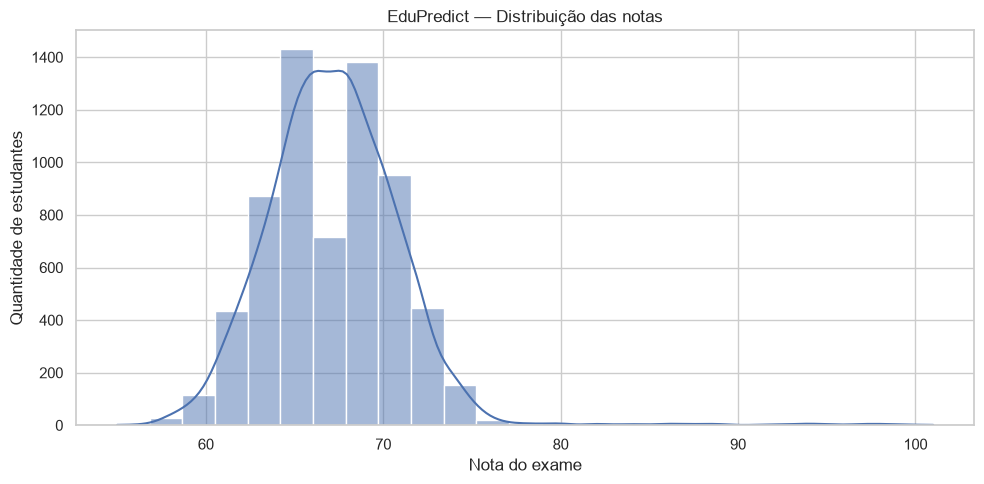

In [6]:

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Exam_Score",
    bins=25,
    kde=True
)

plt.title("EduPredict — Distribuição das notas")
plt.xlabel("Nota do exame")
plt.ylabel("Quantidade de estudantes")
plt.tight_layout()
plt.show()


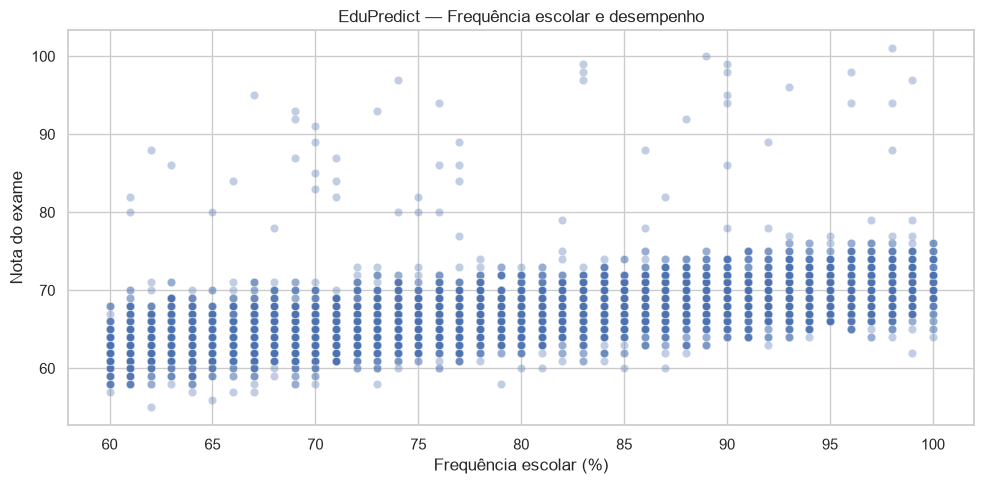

,Hours_Studied,Attendance,Previous_Scores,Exam_Score
Hours_Studied,1.000000,-0.009908,0.024846,0.445455
Attendance,-0.009908,1.000000,-0.020186,0.581072
Previous_Scores,0.024846,-0.020186,1.000000,0.175079
Exam_Score,0.445455,0.581072,0.175079,1.000000


In [7]:

plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x="Attendance",
    y="Exam_Score",
    alpha=0.35
)

plt.title("EduPredict — Frequência escolar e desempenho")
plt.xlabel("Frequência escolar (%)")
plt.ylabel("Nota do exame")
plt.tight_layout()
plt.show()

correlacao = df[
    ["Hours_Studied", "Attendance", "Previous_Scores", "Exam_Score"]
].corr()

display(correlacao)


In [8]:

notas = df["Exam_Score"].dropna()

q33 = notas.quantile(1 / 3)
q67 = notas.quantile(2 / 3)

print("=== PONTOS DE CORTE ===")
print(f"Percentil 33,3%: {q33:.2f}")
print(f"Percentil 66,7%: {q67:.2f}")

print("\n=== NOTAS MAIS FREQUENTES ===")
display(notas.value_counts().head(15).to_frame("Quantidade"))

print("\n=== VALORES DISTINTOS ===")
print(notas.nunique())


=== PONTOS DE CORTE ===
Percentil 33,3%: 66.00
Percentil 66,7%: 69.00

=== NOTAS MAIS FREQUENTES ===


,Quantidade
Exam_Score,
68,759
66,751
67,717
65,679
69,624
70,542
64,501
71,408
63,371



=== VALORES DISTINTOS ===
45



## 2. Preparação dos dados

Os dados serão separados em 80% para treinamento e 20% para teste.

Os limites das classes de desempenho serão calculados exclusivamente
com as notas do conjunto de treinamento, evitando vazamento de dados.

A variável `Exam_Score` será removida dos atributos preditores.


In [13]:

from sklearn.model_selection import train_test_split

# Remover somente registros sem a variável alvo
dados = df.dropna(subset=["Exam_Score"]).copy()

X = dados.drop(columns=["Exam_Score"])
y_notas = dados["Exam_Score"]

X_train, X_test, y_train_notas, y_test_notas = train_test_split(
    X,
    y_notas,
    test_size=0.20,
    random_state=42
)

print("Registros de treinamento:", len(X_train))
print("Registros de teste:", len(X_test))
print("Atributos preditores:", X_train.shape[1])


Registros de treinamento: 5285
Registros de teste: 1322
Atributos preditores: 19


In [14]:

# Calcular limites somente a partir do treinamento
limite_baixo = y_train_notas.quantile(1 / 3)
limite_alto = y_train_notas.quantile(2 / 3)

if limite_baixo >= limite_alto:
    raise ValueError(
        "Os limites das classes coincidiram. "
        "Será necessário revisar a estratégia."
    )

def classificar_desempenho(nota):
    if nota <= limite_baixo:
        return "BAIXO"
    elif nota <= limite_alto:
        return "MEDIO"
    return "ALTO"

y_train = y_train_notas.apply(classificar_desempenho)
y_test = y_test_notas.apply(classificar_desempenho)

print("Limite inferior:", limite_baixo)
print("Limite superior:", limite_alto)

print("\nDistribuição do treinamento:")
display(y_train.value_counts().to_frame("Quantidade"))

print("\nDistribuição do teste:")
display(y_test.value_counts().to_frame("Quantidade"))

print("\nPercentual por classe no treinamento:")
display(
    (y_train.value_counts(normalize=True) * 100)
    .round(2)
    .to_frame("Percentual (%)")
)


Limite inferior: 66.0
Limite superior: 69.0

Distribuição do treinamento:


,Quantidade
Exam_Score,
BAIXO,2315
MEDIO,1693
ALTO,1277



Distribuição do teste:


,Quantidade
Exam_Score,
BAIXO,567
MEDIO,407
ALTO,348



Percentual por classe no treinamento:


,Percentual (%)
Exam_Score,
BAIXO,43.80
MEDIO,32.03
ALTO,24.16


In [15]:

colunas_numericas = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

colunas_categoricas = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("=== COLUNAS NUMÉRICAS ===")
print(colunas_numericas)

print("\n=== COLUNAS CATEGÓRICAS ===")
print(colunas_categoricas)

print("\nTotal de atributos originais:")
print(len(colunas_numericas) + len(colunas_categoricas))


=== COLUNAS NUMÉRICAS ===
['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity']

=== COLUNAS CATEGÓRICAS ===
['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']

Total de atributos originais:
19


In [16]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

pipeline_numerico = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

pipeline_categorico = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    )
])

preprocessador = ColumnTransformer([
    ("numericos", pipeline_numerico, colunas_numericas),
    ("categoricos", pipeline_categorico, colunas_categoricas)
])

print("Pré-processador configurado com sucesso!")


Pré-processador configurado com sucesso!


In [17]:

from sklearn.neural_network import MLPClassifier

modelo = Pipeline([
    ("preprocessador", preprocessador),
    (
        "mlp",
        MLPClassifier(
            hidden_layer_sizes=(64, 32),
            activation="relu",
            solver="adam",
            alpha=0.001,
            learning_rate_init=0.001,
            max_iter=500,
            early_stopping=True,
            n_iter_no_change=20,
            random_state=42
        )
    )
])

print("Iniciando treinamento da rede neural...")

modelo.fit(X_train, y_train)

print("\nTreinamento concluído!")
print(
    "Épocas executadas:",
    modelo.named_steps["mlp"].n_iter_
)


Iniciando treinamento da rede neural...

Treinamento concluído!
Épocas executadas: 37


In [18]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

y_pred = modelo.predict(X_test)

acuracia = accuracy_score(y_test, y_pred)

print("=== RESULTADOS DO EDUPREDICT ===")
print(f"Acurácia: {acuracia:.2%}")

print("\n=== RELATÓRIO DE CLASSIFICAÇÃO ===")
print(
    classification_report(
        y_test,
        y_pred,
        labels=["BAIXO", "MEDIO", "ALTO"],
        zero_division=0
    )
)


=== RESULTADOS DO EDUPREDICT ===
Acurácia: 96.44%

=== RELATÓRIO DE CLASSIFICAÇÃO ===
              precision    recall  f1-score   support

       BAIXO       0.96      0.98      0.97       567
       MEDIO       0.95      0.94      0.95       407
        ALTO       0.99      0.96      0.97       348

    accuracy                           0.96      1322
   macro avg       0.97      0.96      0.96      1322
weighted avg       0.96      0.96      0.96      1322



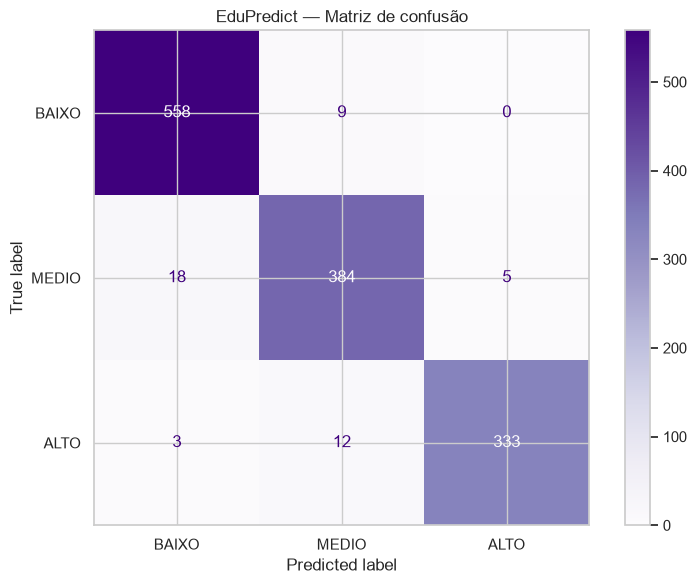

In [19]:

classes = ["BAIXO", "MEDIO", "ALTO"]

matriz = confusion_matrix(
    y_test,
    y_pred,
    labels=classes
)

fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=classes
).plot(
    ax=ax,
    cmap="Purples",
    values_format="d"
)

plt.title("EduPredict — Matriz de confusão")
plt.tight_layout()
plt.show()


In [20]:

from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

pred_baseline = baseline.predict(X_test)

comparacao = pd.DataFrame({
    "Modelo": ["Baseline", "Rede Neural MLP"],
    "Acurácia": [
        accuracy_score(y_test, pred_baseline),
        accuracy_score(y_test, y_pred)
    ],
    "F1 Macro": [
        f1_score(y_test, pred_baseline, average="macro"),
        f1_score(y_test, y_pred, average="macro")
    ]
})

display(comparacao.round(4))


,Modelo,Acurácia,F1 Macro
0,Baseline,0.4289,0.2001
1,Rede Neural MLP,0.9644,0.9635


,Variavel,Importancia,Desvio
1,Attendance,0.488717,0.011955
0,Hours_Studied,0.380039,0.008469
3,Access_to_Resources,0.143851,0.008543
6,Previous_Scores,0.139075,0.006767
2,Parental_Involvement,0.120708,0.002823
9,Tutoring_Sessions,0.109292,0.008304
13,Peer_Influence,0.061120,0.005476
16,Parental_Education_Level,0.059845,0.006676
7,Motivation_Level,0.055133,0.002231
17,Distance_from_Home,0.051597,0.002883


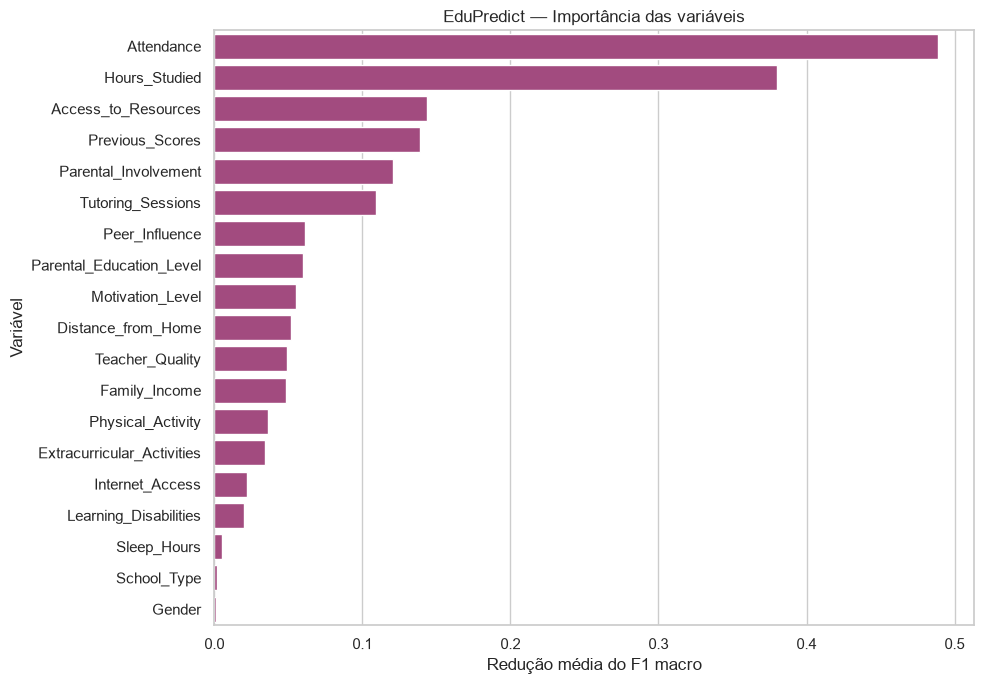

In [21]:

from sklearn.inspection import permutation_importance

importancias = permutation_importance(
    modelo,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=5,
    random_state=42,
    n_jobs=1
)

resultado_importancias = pd.DataFrame({
    "Variavel": X_test.columns,
    "Importancia": importancias.importances_mean,
    "Desvio": importancias.importances_std
}).sort_values("Importancia", ascending=False)

display(resultado_importancias)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=resultado_importancias,
    x="Importancia",
    y="Variavel",
    color="#B13C82"
)

plt.title("EduPredict — Importância das variáveis")
plt.xlabel("Redução média do F1 macro")
plt.ylabel("Variável")
plt.tight_layout()
plt.show()


In [22]:

analise_erros = X_test.copy()

analise_erros["Nota_Real"] = y_test_notas
analise_erros["Classe_Real"] = y_test
analise_erros["Classe_Prevista"] = y_pred

erros = analise_erros[
    analise_erros["Classe_Real"] !=
    analise_erros["Classe_Prevista"]
]

print("=== ANÁLISE DE ERROS ===")
print("Total de previsões incorretas:", len(erros))

print(
    "Percentual de erros:",
    f"{len(erros) / len(X_test):.2%}"
)

display(
    erros[
        [
            "Hours_Studied",
            "Attendance",
            "Previous_Scores",
            "Nota_Real",
            "Classe_Real",
            "Classe_Prevista"
        ]
    ].head(15)
)


=== ANÁLISE DE ERROS ===
Total de previsões incorretas: 47
Percentual de erros: 3.56%


,Hours_Studied,Attendance,Previous_Scores,Nota_Real,Classe_Real,Classe_Prevista
217,19,70,54,89,ALTO,BAIXO
5381,16,93,81,67,MEDIO,BAIXO
4986,19,96,71,70,ALTO,MEDIO
2441,28,65,59,67,MEDIO,BAIXO
503,23,80,91,70,ALTO,MEDIO
5013,19,79,76,67,MEDIO,BAIXO
5416,18,76,82,67,MEDIO,BAIXO
4438,18,75,87,67,MEDIO,BAIXO
6042,33,61,96,67,MEDIO,BAIXO
3250,24,99,51,70,ALTO,MEDIO


In [23]:

import joblib
import sklearn

# Encontrar a raiz do projeto
raiz_projeto = caminho_dataset.parent.parent

diretorio_modelos = raiz_projeto / "models"
diretorio_modelos.mkdir(parents=True, exist_ok=True)

caminho_modelo = diretorio_modelos / "modelo_mlp.joblib"

artefato = {
    "modelo": modelo,
    "colunas_entrada": X_train.columns.tolist(),
    "limites_desempenho": {
        "baixo": float(limite_baixo),
        "alto": float(limite_alto)
    },
    "classes": modelo.classes_.tolist(),
    "versao_sklearn": sklearn.__version__,
    "acuracia_teste": float(acuracia),
    "descricao": "EduPredict - Classificacao de desempenho academico"
}

joblib.dump(artefato, caminho_modelo)

print("Modelo salvo com sucesso!")
print("Arquivo:", caminho_modelo)
print(
    "Tamanho:",
    round(caminho_modelo.stat().st_size / 1024, 2),
    "KB"
)


Modelo salvo com sucesso!
Arquivo: d:\Users\LucasLiSan\Documents\codes\at2AM\models\modelo_mlp.joblib
Tamanho: 128.43 KB


In [24]:

artefato_carregado = joblib.load(caminho_modelo)

modelo_carregado = artefato_carregado["modelo"]

amostra = X_test.iloc[[0]]

resultado = modelo_carregado.predict(amostra)[0]
probabilidades = modelo_carregado.predict_proba(amostra)[0]

print("=== TESTE DO MODELO EXPORTADO ===")
print("Classe prevista:", resultado)

for classe, probabilidade in zip(
    modelo_carregado.classes_,
    probabilidades
):
    print(f"{classe}: {probabilidade:.2%}")

print("\nModelo carregado e testado com sucesso!")


=== TESTE DO MODELO EXPORTADO ===
Classe prevista: BAIXO
ALTO: 0.00%
BAIXO: 99.93%
MEDIO: 0.07%

Modelo carregado e testado com sucesso!
